In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

Exception ignored in PyObject_HasAttr(); consider using PyObject_HasAttrWithError(), PyObject_GetOptionalAttr() or PyObject_GetAttr():
Traceback (most recent call last):
  File "<frozen importlib._bootstrap>", line 491, in _call_with_frames_removed
AttributeError: partially initialized module 'pandas' from 'c:\Users\jimmi\AppData\Local\Programs\Python\Python314\Lib\site-packages\pandas\__init__.py' has no attribute '_pandas_parser_CAPI' (most likely due to a circular import)


In [4]:
X, _ = make_blobs(
    n_samples=600,
    centers=5,
    cluster_std=0.85,
    random_state=42
)

df = pd.DataFrame(X, columns=["Annual_Income", "Spending_Score"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

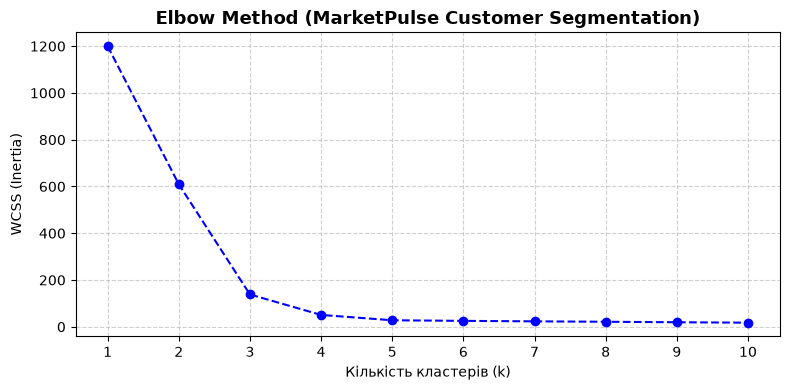

In [5]:
wcss = []
cluster_range = range(1, 11)

for k in cluster_range:
    kmeans_test = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    kmeans_test.fit(X_scaled)
    wcss.append(kmeans_test.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(cluster_range, wcss, marker='o', linestyle='--', color='b')
plt.title("Elbow Method (MarketPulse Customer Segmentation)", fontsize=13, fontweight="bold")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(cluster_range)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("elbow_method.png", dpi=300)
plt.show()

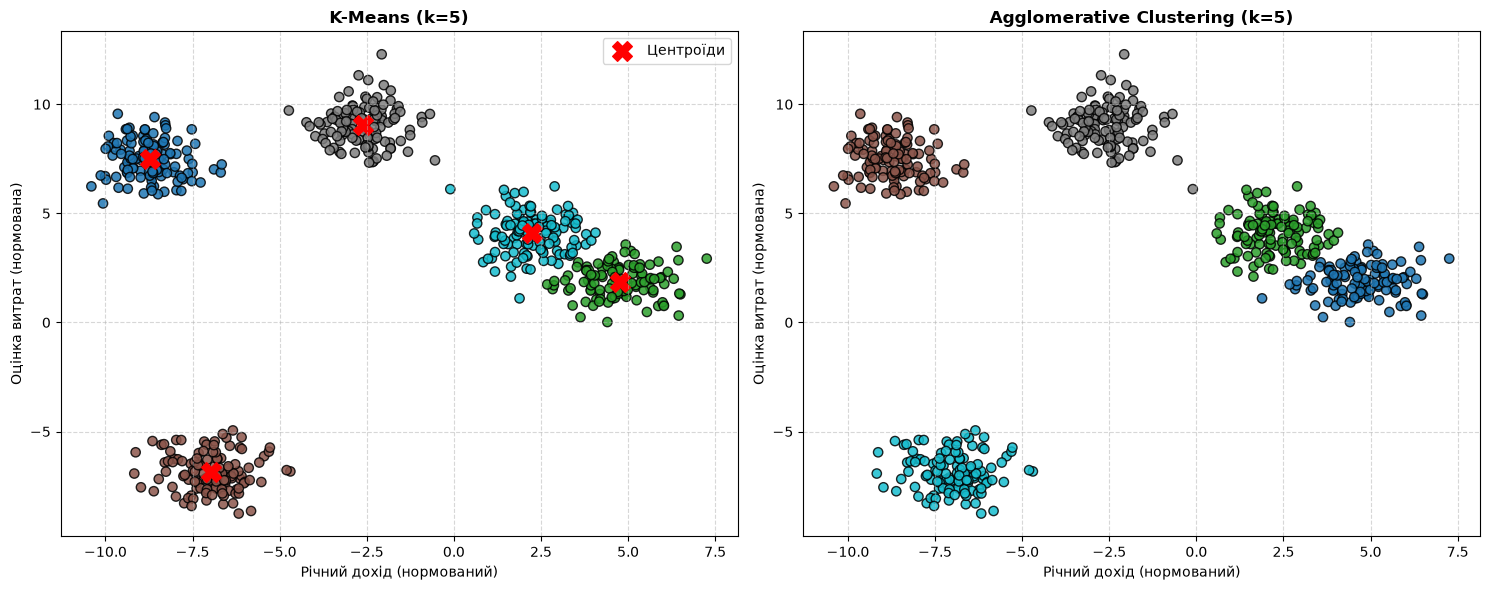

In [ ]:
optimal_k = 5

kmeans = KMeans(n_clusters=optimal_k, init="k-means++", n_init=10, random_state=42)
df["Cluster_KMeans"] = kmeans.fit_predict(X_scaled)

agg = AgglomerativeClustering(n_clusters=optimal_k, metric="euclidean", linkage="ward")
df["Cluster_Agglomerative"] = agg.fit_predict(X_scaled)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster_KMeans"],
    cmap="tab10",
    marker="o",
    edgecolor="k",
    s=45,
    alpha=0.85
)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
ax1.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Центроїди"
)
ax1.set_title(f"K-Means (k={optimal_k})", fontsize=12, fontweight="bold")
ax1.set_xlabel("Річний дохід (нормований)")
ax1.set_ylabel("Оцінка витрат (нормована)")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster_Agglomerative"],
    cmap="tab10",
    marker="o",
    edgecolor="k",
    s=45,
    alpha=0.85
)
ax2.set_title(f"Agglomerative Clustering (k={optimal_k})", fontsize=12, fontweight="bold")
ax2.set_xlabel("Річний дохід (нормований)")
ax2.set_ylabel("Оцінка витрат (нормована)")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("clustering_comparison_marketpulse.png", dpi=300)
plt.show()